In [1]:
%pip install -U microlens_submit
%pip install -U RTModel==3.3
%pip install -U jacscanomaly
%pip install -U microjax
%pip uninstall -U pyAethra
%pip install -U pyAethra

%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.

[optparse.groups]Usage:[/]   
  /opt/conda/bin/python -m pip uninstall \[options] <package> ...
  /opt/conda/bin/python -m pip uninstall \[options] -r <requirements file> ...

no such option: -U
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
# system imports
import os
import time
import sys
from pathlib import Path
from tqdm import tqdm

# data access imports
from huggingface_hub import hf_hub_download
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u

# display imports
from IPython.display import HTML

# multiprocessing imports
import multiprocessing as mp
from multiprocessing.pool import ThreadPool

# data challenge imports
import microlens_submit
#import MulensModel
#from pyLIMA.pyLIMASS import SourceLensProbabilities
import RTModel

# data analysis/visualization imports
import numpy as np
import matplotlib.pyplot as plt

# detection packages
from pyAethra import load_config, load_and_run
from jacscanomaly import CandidateCriteria, Finder, FinderConfig

root_dir = '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople'

In [4]:
import pyAethra
print(pyAethra.__version__)
import jacscanomaly
print(jacscanomaly.__version__)
print(sys.version)
print(np.__version__)


0.1.1
0.5.1
3.12.12 | packaged by conda-forge | (main, Jan 26 2026, 23:51:32) [GCC 14.3.0]
2.4.2


In [5]:
%pip install datasets pandas pyarrow duckdb huggingface_hub


/opt/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Note: you may need to restart the kernel to use updated packages.


In [6]:
from datasets import load_dataset
import os

os.environ["HF_TOKEN"] = "hf_your_token_here" # will replace before pushing; dear teammates: please don't compromise me

token = os.environ.get("HF_TOKEN")
assert token, "Set HF_TOKEN environment variable first"

# con.execute("""
#     CREATE SECRET hf_token (
#         TYPE HUGGINGFACE,
#         PROVIDER credential_chain
#     );
# """)

dataset_name = "RGES-PIT/MachineLearning"

# Load metadata and epochs tables (which fit easily in RAM)
meta_df = load_dataset(dataset_name, "metadata", split="train", token=token).to_pandas()
epochs_df = load_dataset(dataset_name, "epochs", split="train", token=token).to_pandas()

print(f"Metadata     : {meta_df.shape[0]:,} rows")
print(f"Epochs       : {epochs_df.shape[0]:,} rows")

Metadata     : 377,999 rows
Epochs       : 98,974 rows


In [7]:
import duckdb
from huggingface_hub import HfFileSystem
import os

token = os.environ.get("HF_TOKEN")
con = duckdb.connect()
con.register_filesystem(HfFileSystem(token=token))

obs_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_obs.parquet"
meta_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_meta.parquet"
epoch_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_epoch.parquet"

event_id = 3000

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        m.tE_helio,
        m.sim_label
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.event_id = {event_id}
    ORDER BY e.bjd
""").df()

print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")
print(f"  {len(event_obs):,} observations")
print(f"  Einstein timescale tE_helio = {abs(event_obs['tE_helio'].iloc[0]):.2f} days")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 3000: RMDC26_003000 (RMDC26_1S1L_ML)
  49,488 observations
  Einstein timescale tE_helio = 3.55 days


### The first seven days: 1L1S events --> FFPs
See https://docs.google.com/document/d/1-ArUqzkGXTsjjOladYsV3BgF8Il6RyF5TRPrEf8Y3eQ/edit?tab=t.0 for full notes

In [9]:
meta_df_1s1l = meta_df.loc[(meta_df['sim_label']=='RMDC26_1S1L_ML')]
meta_df_1s1l

,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,Source_Fe_H,Source2_Mass,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213
0,RMDC26_003000,3000,RMDC26_1S1L_ML,0.0,633.0,1936.0,0.012366,66.744210,2.462736e+06,3.585315,...,0.319104,NaN,NaN,NaN,NaN,NaN,False,2.061971,5.147735,0.692188
1,RMDC26_003016,3016,RMDC26_1S1L_ML,0.0,718.0,7002.0,0.021194,13124.511426,2.462735e+06,0.214467,...,0.120387,NaN,NaN,NaN,NaN,NaN,False,0.483870,1.207987,0.162431
2,RMDC26_003032,3032,RMDC26_1S1L_ML,0.0,874.0,572.0,0.016154,3438.811691,2.461841e+06,0.051493,...,-0.556216,NaN,NaN,NaN,NaN,NaN,False,0.848105,2.117306,0.284703
3,RMDC26_003048,3048,RMDC26_1S1L_ML,2.0,0.0,4028.0,0.013090,379.330478,2.461504e+06,14.050508,...,0.080757,NaN,NaN,NaN,NaN,NaN,False,3.180586,7.940372,1.067699
4,RMDC26_003064,3064,RMDC26_1S1L_ML,1.0,21.0,7425.0,0.034964,103.546626,2.461713e+06,36.203618,...,-0.110039,NaN,NaN,NaN,NaN,NaN,True,2.581654,6.445132,0.866642
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373086,RMDC26_306375,306375,RMDC26_1S1L_ML,1.0,676.0,4437.0,0.012477,26835.710390,2.461653e+06,0.071499,...,0.275095,NaN,NaN,NaN,NaN,NaN,False,0.742187,1.852880,0.249147
373087,RMDC26_306391,306391,RMDC26_1S1L_ML,0.0,598.0,7263.0,0.048676,47962.259643,2.462957e+06,1.468066,...,0.211120,NaN,NaN,NaN,NaN,NaN,False,0.449580,1.122381,0.150921
373088,RMDC26_306407,306407,RMDC26_1S1L_ML,1.0,88.0,9926.0,0.863027,94.722852,2.462837e+06,52.013203,...,-0.446141,NaN,NaN,NaN,NaN,NaN,True,0.488442,1.219401,0.163966
373089,RMDC26_306423,306423,RMDC26_1S1L_ML,1.0,673.0,7090.0,0.014256,437852.475921,2.461505e+06,14.545849,...,-0.449106,NaN,NaN,NaN,NaN,NaN,False,2.590036,6.466057,0.869456


                 name  event_id       sim_label  SubRun  Field  EventID  \
1       RMDC26_003016      3016  RMDC26_1S1L_ML     0.0  718.0   7002.0   
2       RMDC26_003032      3032  RMDC26_1S1L_ML     0.0  874.0    572.0   
8       RMDC26_003128      3128  RMDC26_1S1L_ML     0.0  840.0   8457.0   
9       RMDC26_003144      3144  RMDC26_1S1L_ML     0.0   86.0   3155.0   
16      RMDC26_003272      3272  RMDC26_1S1L_ML     1.0  913.0    360.0   
...               ...       ...             ...     ...    ...      ...   
373070  RMDC26_306119    306119  RMDC26_1S1L_ML     1.0  639.0   9517.0   
373072  RMDC26_306151    306151  RMDC26_1S1L_ML     1.0  755.0   2030.0   
373075  RMDC26_306199    306199  RMDC26_1S1L_ML     0.0  755.0   6716.0   
373083  RMDC26_306327    306327  RMDC26_1S1L_ML     0.0   46.0   8781.0   
373086  RMDC26_306375    306375  RMDC26_1S1L_ML     1.0  676.0   4437.0   

        final_weight  ObsGroup_0_chi2       t0lens1    tE_ref  ...  \
1           0.021194     1312

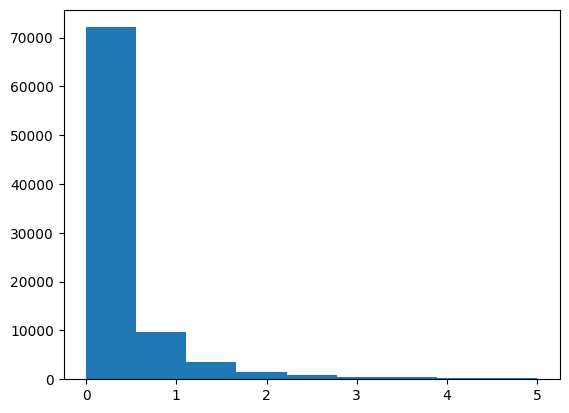

In [11]:
meta_df_1s1l_planets = meta_df_1s1l.loc[meta_df_1s1l['Lens_Mass']<1e-3]
print(meta_df_1s1l_planets)
plt.hist(meta_df_1s1l_planets['tE_ref'], bins=np.linspace(0,5,10))
plt.show()

In [12]:
event_ids = np.unique(meta_df_1s1l_planets['event_id'])

In [ ]:
init_t = 11447.757211620454 # BJD-2450000

In [32]:
init_t + 7

11454.757211620454

In [44]:
meta_df_1s1l_planets_first_week = meta_df_1s1l_planets.loc[meta_df_1s1l_planets['t0lens1']-2*meta_df_1s1l_planets['tE_ref'] - 2450000 <= init_t + 7]
event_ids_first_week = np.unique(meta_df_1s1l_planets_first_week['event_id'])
meta_df_1s1l_planets_first_week

,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,Source_Fe_H,Source2_Mass,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213
167,RMDC26_005688,5688,RMDC26_1S1L_ML,0.0,122.0,4423.0,0.001831,251.599394,2.461451e+06,0.414394,...,0.085368,NaN,NaN,NaN,NaN,NaN,False,2.213608,5.526301,0.743092
195,RMDC26_006136,6136,RMDC26_1S1L_ML,1.0,128.0,7612.0,0.004837,360.036688,2.461441e+06,3.324915,...,0.115291,NaN,NaN,NaN,NaN,NaN,True,0.473202,1.181354,0.158850
255,RMDC26_007096,7096,RMDC26_1S1L_ML,0.0,639.0,9929.0,0.012042,39223.845240,2.461448e+06,0.255878,...,0.028577,NaN,NaN,NaN,NaN,NaN,False,0.315468,0.787569,0.105900
494,RMDC26_010952,10952,RMDC26_1S1L_ML,1.0,913.0,2408.0,0.012004,271.017617,2.461459e+06,3.561762,...,-0.374598,NaN,NaN,NaN,NaN,NaN,False,1.344167,3.355730,0.451227
601,RMDC26_012680,12680,RMDC26_1S1L_ML,1.0,674.0,8278.0,0.031706,82.520551,2.461451e+06,0.392476,...,-0.477054,NaN,NaN,NaN,NaN,NaN,False,1.168145,2.916289,0.392138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
371739,RMDC26_284567,284567,RMDC26_1S1L_ML,0.0,8.0,264.0,0.003950,97.832791,2.461452e+06,0.187782,...,0.049714,NaN,NaN,NaN,NaN,NaN,False,0.436626,1.090041,0.146572
372005,RMDC26_288871,288871,RMDC26_1S1L_ML,0.0,839.0,4587.0,0.000232,814.674688,2.461450e+06,0.029859,...,-0.629005,NaN,NaN,NaN,NaN,NaN,False,0.380238,0.949268,0.127643
372452,RMDC26_296103,296103,RMDC26_1S1L_ML,1.0,598.0,7114.0,0.010275,11194.397942,2.461453e+06,0.609868,...,0.556799,NaN,NaN,NaN,NaN,NaN,False,0.449580,1.122381,0.150921
372855,RMDC26_302647,302647,RMDC26_1S1L_ML,1.0,875.0,2760.0,0.058295,231.695311,2.461450e+06,0.321759,...,-0.477376,NaN,NaN,NaN,NaN,NaN,False,0.742187,1.852880,0.249147


For each event, grab only the first seven days of Season 1 (fake) data and run pyAethra on it

In [13]:
aethra_config = load_config(root_dir+"/config/aethra_config_flux.yaml") # courtesy of Katie Vandorou


In [19]:
names, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores = [], [], [], [], [], [], []

In [26]:
def detection_individual(lc_data, f146_df):#, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores):#, ss, qs, alphas, rhos):

    ### EVENT DETECTION WITH PYAETHRA
    aethra_results_df = load_and_run(lc_data, aethra_config)
    label = aethra_results_df['label'].iloc[0]
    print("label: ", label)

    ### this is logic for proceeding to next event in the loop if pyAethra fails to find a bound or free-floating planet candidate
    if (label != 'microlensing') and (label != 'ffp'):
        t0_fit=np.nan
        tE_fit=np.nan
        u0_fit=np.nan
        t0_anomaly=np.nan
        jacscanomaly_score=np.nan
    else:
        t0_fit = aethra_results_df['t0_fit'].iloc[0]
        u0_fit = aethra_results_df['u0_fit'].iloc[0]
        tE_fit = aethra_results_df['tE_fit'].iloc[0]
        print(aethra_results_df)
        print("t0: ", t0_fit)
        print("u0: ", u0_fit)
        print("tE: ", tE_fit)

        # not sure what's wrong with pyAethra or my config, but it just doesn't want to label anything an 'ffp'
        # so let's manually change 'microlensing' to 'ffp' based on ffp_tE_max
        #if tE_fit <= ffp_tE_max:
        #    label = 'ffp'

        # if pyAethra spits out NaNs for t0, tE, u0, move on
        if t0_fit != t0_fit: 
            jacscanomaly_score=np.nan
            t0_anomaly=np.nan
            return label, t0_fit, tE_fit, u0_fit, t0_anomaly, jacscanomaly_score

        ### ANOMALY DETECTION WITH JACSCANOMALY
        time = np.array(f146_df["bjd"])
        flux = np.array(f146_df["flux_uJy"])
        fluxerr = np.array(f146_df["flux_err_uJy"])

        criteria = CandidateCriteria(
            min_dchi2=20.0, 
            min_n_eff=2.0,
            #min_n_contrib=2,
            #max_peak_frac=0.8,
        )
        jacscanomaly_config = FinderConfig(
            fitter_kind="pspl",
            candidate_criteria=criteria, # candidate_criteria=CandidateCriteria(min_n_eff=2.0)
            gap=150.0 # default is 50. gap between seasons is ~half a year, hence 150
        )
        finder = Finder(jacscanomaly_config)

        # initial guess is from aethra
        p0 = np.array([t0_fit, tE_fit, u0_fit]) 

        # actually run the anomaly finder. Make sure you're distinguishing between magnitude and flux. Beginner tier uses mag; experienced+ tiers use flux.
        print("running jacscanomaly...")
        anomaly_result = finder.run(time, flux, fluxerr, p0, data_kind="mag")
        #anomaly_result.print_summary()
        anomaly_result_summary = anomaly_result.summary_table()
        #print(anomaly_result_summary)

        # grab relevant variables
        t0_fit_best = anomaly_result_summary['best_t0'].values[0]
        print("t0_fit_best: ", t0_fit_best)

        jacscanomaly_score = anomaly_result_summary['best_score'].values[0]
        print("best score: ", jacscanomaly_score)

        # this is where I skip to the next event, if jacscanomaly finds nothing
        if jacscanomaly_score < 10:
            print("does not pass score threshold of 10")
            t0_anomaly = np.nan
        else:
            t0_anomaly = anomaly_result_summary['best_t0'].values[0]

    return label, t0_fit, tE_fit, u0_fit, t0_anomaly, jacscanomaly_score
    

  0%|          | 0/1611 [00:00<?, ?it/s]

4125


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 4125: RMDC26_004125 (RMDC26_1S1L_ML)
  49,488 observations
  Einstein timescale tE_helio = 0.01 days
  Einstein timescale tE_ref = 0.01 days
  impact parameter u0lens1 = 2.24
     event_id           name           bjd  filt   flux_uJy  flux_err_uJy  \
0        4125  RMDC26_004125  2.461448e+06  F146  19.607193      0.159512   
1        4125  RMDC26_004125  2.461448e+06  F146  19.282074      0.159512   
2        4125  RMDC26_004125  2.461448e+06  F213  60.608295      0.609802   
3        4125  RMDC26_004125  2.461448e+06  F146  19.592155      0.159512   
4        4125  RMDC26_004125  2.461448e+06  F146  19.560006      0.159512   
..        ...            ...           ...   ...        ...           ...   
766      4125  RMDC26_004125  2.461455e+06  F146  19.417929      0.159512   
767      4125  RMDC26_004125  2.461455e+06  F146  19.682899      0.159512   
768      4125  RMDC26_004125  2.461455e+06  F146  19.582821      0.159512   
769      4125  RMDC26_004125  2.461455e+06  F146 

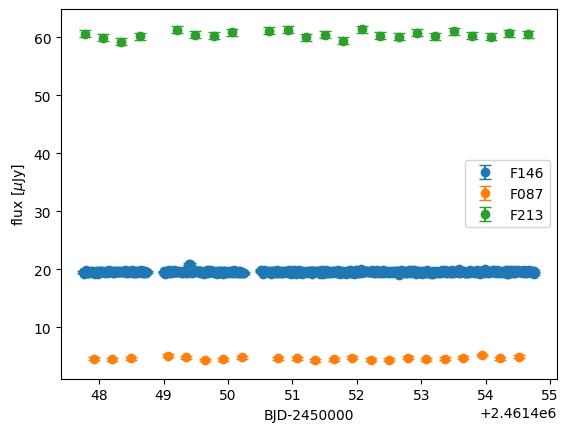

  771 rows, columns: ['event_id', 'name', 'bjd', 'filt', 'flux_uJy', 'flux_err_uJy', 't0lens1', 'tE_helio', 'tE_ref', 'u0lens1', 'sim_label', 'bjd-2450000']
label:  flat
nan
nan
     event_id           name           bjd  filt   flux_uJy  flux_err_uJy  \
0        4125  RMDC26_004125  2.461448e+06  F146  19.607193      0.159512   
1        4125  RMDC26_004125  2.461448e+06  F146  19.282074      0.159512   
3        4125  RMDC26_004125  2.461448e+06  F146  19.592155      0.159512   
4        4125  RMDC26_004125  2.461448e+06  F146  19.560006      0.159512   
5        4125  RMDC26_004125  2.461448e+06  F146  19.838457      0.159512   
..        ...            ...           ...   ...        ...           ...   
766      4125  RMDC26_004125  2.461455e+06  F146  19.417929      0.159512   
767      4125  RMDC26_004125  2.461455e+06  F146  19.682899      0.159512   
768      4125  RMDC26_004125  2.461455e+06  F146  19.582821      0.159512   
769      4125  RMDC26_004125  2.461455e+06  F146  19

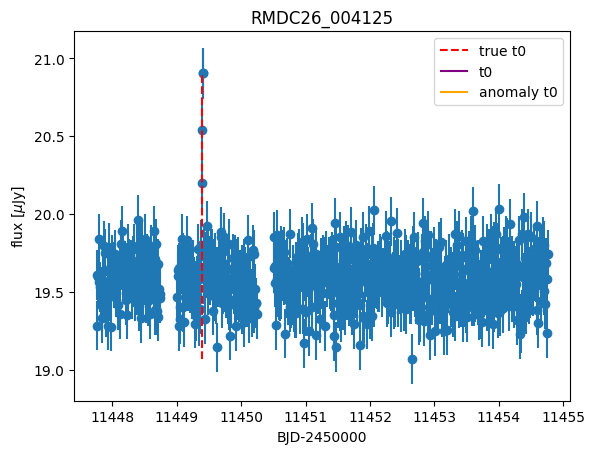

  0%|          | 1/1611 [00:05<2:24:31,  5.39s/it]

4403


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 4403: RMDC26_004403 (RMDC26_1S1L_ML)
  49,488 observations
  Einstein timescale tE_helio = 1.17 days
  Einstein timescale tE_ref = 1.19 days
  impact parameter u0lens1 = 0.08
     event_id           name           bjd  filt   flux_uJy  flux_err_uJy  \
0        4403  RMDC26_004403  2.461448e+06  F146   6.211874      0.134435   
1        4403  RMDC26_004403  2.461448e+06  F146   6.409421      0.134438   
2        4403  RMDC26_004403  2.461448e+06  F213  75.220297      0.638598   
3        4403  RMDC26_004403  2.461448e+06  F146   6.088795      0.134442   
4        4403  RMDC26_004403  2.461448e+06  F146   6.233077      0.134445   
..        ...            ...           ...   ...        ...           ...   
766      4403  RMDC26_004403  2.461455e+06  F146   6.030358      0.134235   
767      4403  RMDC26_004403  2.461455e+06  F146   6.029841      0.134235   
768      4403  RMDC26_004403  2.461455e+06  F146   5.961579      0.134235   
769      4403  RMDC26_004403  2.461455e+06  F146 

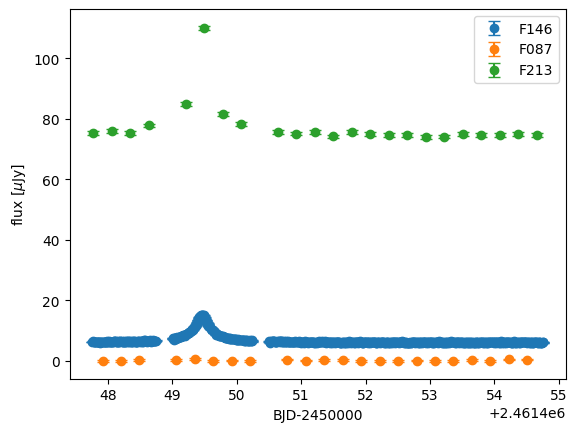

  771 rows, columns: ['event_id', 'name', 'bjd', 'filt', 'flux_uJy', 'flux_err_uJy', 't0lens1', 'tE_helio', 'tE_ref', 'u0lens1', 'sim_label', 'bjd-2450000']
label:  ffp
            name label  periodic  recurrent  chromatic  best_season  is_flat  \
0  RMDC26_004403   ffp     False      False      False            1    False   

      chi2_flat  dof_flat  chi2_red_flat  ...    bump_snr        t0_fit  \
0  82547.094386       725     113.858061  ...  185.653686  11449.460953   

     u0_fit    tE_fit  chi2_red_pspl  baseline_flux  peak_flux  baseline_mag  \
0  0.075269  1.143964        0.97526       6.216528  15.242155      -1.98387   

   peak_mag  scan_candidate  
0 -2.957616            True  

[1 rows x 21 columns]
t0:  11449.46095336182
u0:  0.0752686480730154
tE:  1.1439637953301212
running jacscanomaly...
t0_fit_best:  2461449.474581094
best score:  nan
11449.46095336182
2461449.474581094
     event_id           name           bjd  filt  flux_uJy  flux_err_uJy  \
0        4403  RMDC

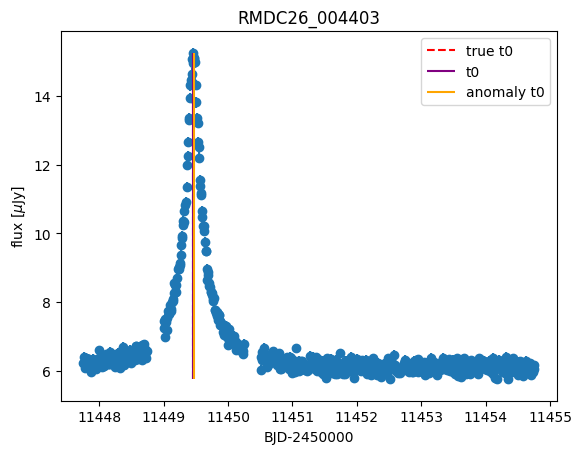

  0%|          | 2/1611 [00:08<1:53:43,  4.24s/it]

4422
Event 4422: RMDC26_004422 (RMDC26_1S1L_ML)
  49,488 observations
  Einstein timescale tE_helio = 0.57 days
  Einstein timescale tE_ref = 0.52 days
  impact parameter u0lens1 = 0.03
     event_id           name           bjd  filt   flux_uJy  flux_err_uJy  \
0        4422  RMDC26_004422  2.461448e+06  F146   1.339823      0.122316   
1        4422  RMDC26_004422  2.461448e+06  F146   1.454897      0.122325   
2        4422  RMDC26_004422  2.461448e+06  F213  39.292961      0.555651   
3        4422  RMDC26_004422  2.461448e+06  F146   1.322081      0.122344   
4        4422  RMDC26_004422  2.461448e+06  F146   1.395586      0.122354   
..        ...            ...           ...   ...        ...           ...   
766      4422  RMDC26_004422  2.461455e+06  F146   1.294199      0.122047   
767      4422  RMDC26_004422  2.461455e+06  F146   1.292172      0.122047   
768      4422  RMDC26_004422  2.461455e+06  F146   1.467063      0.122047   
769      4422  RMDC26_004422  2.461455e+06  

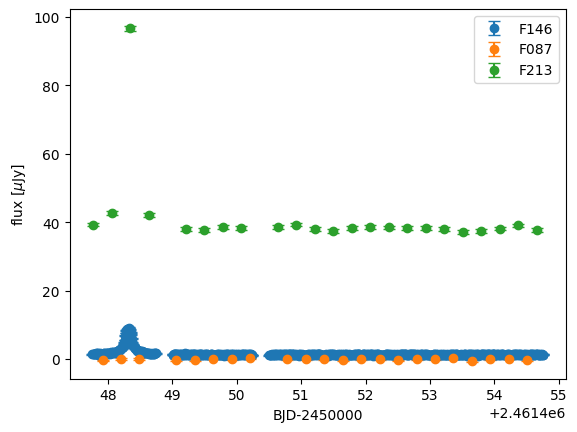

  771 rows, columns: ['event_id', 'name', 'bjd', 'filt', 'flux_uJy', 'flux_err_uJy', 't0lens1', 'tE_helio', 'tE_ref', 'u0lens1', 'sim_label', 'bjd-2450000']
label:  ffp
            name label  periodic  recurrent  chromatic  best_season  is_flat  \
0  RMDC26_004422   ffp     False      False      False            1    False   

      chi2_flat  dof_flat  chi2_red_flat  ...   bump_snr        t0_fit  \
0  37691.200848       725      51.987863  ...  79.411796  11448.319041   

     u0_fit    tE_fit  chi2_red_pspl  baseline_flux  peak_flux  baseline_mag  \
0  0.187242  0.219952       1.467521        1.29496   9.078152     -0.280641   

   peak_mag  scan_candidate  
0 -2.394994            True  

[1 rows x 21 columns]
t0:  11448.319041069597
u0:  0.18724232442148853
tE:  0.21995238601246464
running jacscanomaly...
t0_fit_best:  2461448.1388492812
best score:  nan
11448.319041069597
2461448.1388492812
     event_id           name           bjd  filt  flux_uJy  flux_err_uJy  \
0        4422  

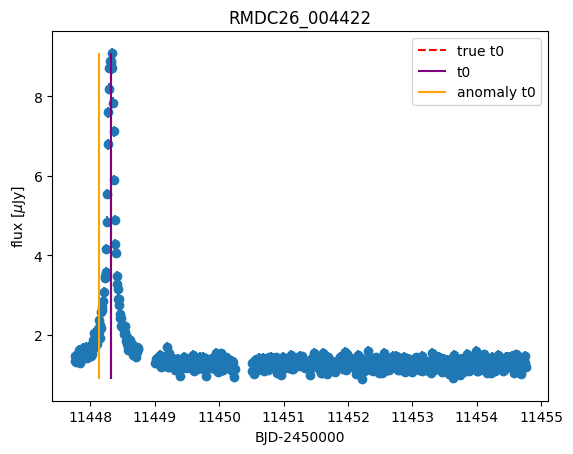

  0%|          | 2/1611 [00:11<2:29:51,  5.59s/it]


In [45]:
early_end = 0
for event_id in tqdm(event_ids_first_week):
    print(event_id)

    # summon the light curve
    # Reconstruct a single event's lightcurve
    event_obs = con.execute(f"""
        SELECT 
            o.event_id,
            m.name,
            e.bjd,
            o.filt,
            o.flux_uJy,
            o.flux_err_uJy,
            m.t0lens1,
            m.tE_helio,
            m.tE_ref,
            m.u0lens1,
            m.sim_label
        FROM '{obs_p}' o
        JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
        JOIN '{meta_p}' m ON o.event_id = m.event_id
        WHERE o.event_id = {event_id}
        ORDER BY e.bjd
    """).df()
    
    print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")
    print(f"  {len(event_obs):,} observations")
    print(f"  Einstein timescale tE_helio = {abs(event_obs['tE_helio'].iloc[0]):.2f} days")
    print(f"  Einstein timescale tE_ref = {abs(event_obs['tE_ref'].iloc[0]):.2f} days")
    print(f"  impact parameter u0lens1 = {abs(event_obs['u0lens1'].iloc[0]):.2f}")

    event_obs['bjd-2450000'] = event_obs['bjd'] - 2450000
    # isolate just the first week of data
    event_obs = event_obs.loc[event_obs['bjd-2450000']<=11447.757211620454 + 7]
    print(event_obs)
    
    t0lens1 = event_obs['t0lens1'].iloc[0]-2450000
    event_obs_filt = event_obs.loc[event_obs['filt']=='F146'] # keep only F146 filter for jacscanomaly

    # plot for slides and stuff
    f146_df = event_obs.loc[event_obs['filt']=='F146']
    f087_df = event_obs.loc[event_obs['filt']=='F087']
    f213_df = event_obs.loc[event_obs['filt']=='F213']
    plt.errorbar(f146_df['bjd'], f146_df['flux_uJy'], f146_df['flux_err_uJy'], linestyle='none', marker='o', capsize=4, label='F146')
    plt.errorbar(f087_df['bjd'], f087_df['flux_uJy'], f087_df['flux_err_uJy'], linestyle='none', marker='o', capsize=4, label='F087')
    plt.errorbar(f213_df['bjd'], f213_df['flux_uJy'], f213_df['flux_err_uJy'], linestyle='none', marker='o', capsize=4, label='F213')
    plt.xlabel('BJD-2450000')
    plt.ylabel(r'flux [$\mu$Jy]')
    plt.legend()
    plt.show()

    # make sure I omit low cadence events
    if (event_obs_filt['t0lens1'].iloc[0]-2450000 >= 11900) & (event_obs_filt['t0lens1'].iloc[0]-2450000 <= 12700):
        print("event seeded in low cadence season")
        label, t0, tE, u0, t0_anomaly, jacscanomaly_score = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
        continue
    else:
        label, t0, tE, u0, t0_anomaly, jacscanomaly_score = detection_individual(event_obs, event_obs_filt)#, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores)

    print(t0)
    print(t0_anomaly)
    #print(f"  cadence = {abs(event_obs_filt['bjd-2450000'].iloc[-2] - event_obs_filt['bjd-2450000'].iloc[-1]):.2f} days")
    print(event_obs_filt)
    print(event_obs_filt['t0lens1'].iloc[0]-2450000)
    plt.errorbar(event_obs_filt['bjd-2450000'], event_obs_filt['flux_uJy'], event_obs_filt['flux_err_uJy'], fmt='o', linestyle='None')
    plt.vlines(event_obs_filt['t0lens1'].iloc[0]-2450000, min(event_obs_filt['flux_uJy']), max(event_obs_filt['flux_uJy']), colors='r', linestyles='--', label='true t0', zorder=100)
    plt.vlines(t0, min(event_obs_filt['flux_uJy']), max(event_obs_filt['flux_uJy']), colors='purple', linestyles='solid', label='t0', zorder=100)
    plt.vlines(t0_anomaly-2450000, min(event_obs_filt['flux_uJy']), max(event_obs_filt['flux_uJy']), colors='orange', linestyles='solid', label='anomaly t0', zorder=100)
    plt.ylabel(r'flux [$\mu$Jy]')
    plt.xlabel('BJD-2450000')        
    #plt.xlim([event_obs_filt['t0lens1'].iloc[0]-2450000-3*event_obs_filt['tE_helio'].iloc[0], event_obs_filt['t0lens1'].iloc[0]-2450000+3*event_obs_filt['tE_helio'].iloc[0]])
    plt.title(f"{event_obs['name'].iloc[0]}")
    plt.legend()
    plt.show()
    
    # labels.append(label)
    # t0s.append(t0)
    # tEs.append(tE)
    # u0s.append(u0)
    # t0_anomalies.append(t0_anomaly)
    # jacscanomaly_scores.append(jacscanomaly_score)

    early_end += 1

    if early_end == 3:
        break